# Day 11 — What-If Pricing Simulator

This notebook builds a scenario-based pricing simulator using the validated DML price-effect
coefficient from Day 10. For a selected baseline product-store observation, it generates
candidate prices at ±5% and ±10% around the baseline and estimates demand and revenue
for each scenario.

---

> **How the simulator works:** The DML coefficient θ estimates how many units sold change
> on average for a one-dollar increase in price, after partialling out observed controls.
> Given a baseline observation (price₀, units₀), we approximate demand at a new price p
> as:  **units_est(p) ≈ units₀ + θ × (p − price₀)**
> This is a **local linear approximation** valid near the baseline price.
> It is not a full demand model and extrapolation to distant prices is unreliable.

> **Revenue vs Profit:** Revenue = price × quantity. Profit = revenue − cost.
> Unit cost is not available in this dataset. Revenue maximisation does not imply
> profit maximisation. Do not use this simulator for automatic pricing decisions.

In [1]:
# Cell 1: Imports
import warnings
warnings.filterwarnings('ignore')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path.home() / 'Documents' / 'EconoCausal'
print('Imports complete. Project root:', PROJECT_ROOT)

Imports complete. Project root: /Users/hasikaippili/Documents/EconoCausal


## 1 · Load Validated DML Results from Day 10

In [2]:
# Cell 2: Load Day 10 validated coefficient
RESULTS_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dml_validated_results.json'

if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f'Day 10 validated results not found at {RESULTS_PATH}.\n'
        'Please run notebook 08_dml_validation.ipynb first.'
    )

with open(RESULTS_PATH, 'r') as f:
    dml_results = json.load(f)

if not dml_results.get('validated', False):
    raise ValueError(
        'The loaded DML results are not marked as validated. '
        'Re-run notebook 08_dml_validation.ipynb.'
    )

# Use Spec 1 (core controls) as the primary estimate
spec = dml_results['spec1']
THETA    = spec['theta']
CI_LOW   = spec['ci_low']
CI_HIGH  = spec['ci_high']
STD_ERR  = spec['std_err']
P_VALUE  = spec['p_value']
N_OBS    = spec['n_obs']
T_RES_SD = spec['t_res_std']

print('Day 10 validated DML results loaded (Spec 1 - core controls):')
print(f'  theta (DML coeff)  : {THETA:+.6f}  units / $1 price change')
print(f'  95% CI             : [{CI_LOW:.6f}, {CI_HIGH:.6f}]')
print(f'  Std Error (HC3)    : {STD_ERR:.6f}')
print(f'  p-value            : {P_VALUE:.4f}')
print(f'  Sample size        : {N_OBS:,}')
print(f'  Price residual SD  : {T_RES_SD:.4f}')
print(f"  Note               : {dml_results['note']}")

# Reliability warnings
if T_RES_SD < 1.0:
    print('\n WARNING: Residual price variation is very small. Coefficient may be unreliable.')
if P_VALUE > 0.10:
    print(f'\n WARNING: p-value = {P_VALUE:.4f}. The price effect is not '
          'statistically significant. Treat simulator outputs with caution.')

# Spec 2 sensitivity
theta2 = dml_results['spec2']['theta']
coeff_shift = abs(THETA - theta2)
pct_shift = abs(coeff_shift / THETA) * 100 if THETA != 0 else float('inf')
print(f'\n  Spec 2 coefficient (sensitivity): {theta2:+.6f}')
print(f'  Absolute shift vs Spec 1        : {coeff_shift:.6f}')
if pct_shift > 25:
    print(f'  WARNING: Coefficient is sensitive to control selection ({pct_shift:.1f}% shift).')

Day 10 validated DML results loaded (Spec 1 - core controls):
  theta (DML coeff)  : +0.010699  units / $1 price change
  95% CI             : [-0.019671, 0.041069]
  Std Error (HC3)    : 0.015495
  p-value            : 0.4899
  Sample size        : 73,100
  Price residual SD  : 26.3743
  Note               : Spec 1 is the primary estimate. Spec 2 is a sensitivity check only. HC3 standard errors. 3-fold cross-fitting with ExtraTreesRegressor. Results are observational, not necessarily causal.


  Spec 2 coefficient (sensitivity): -0.019468
  Absolute shift vs Spec 1        : 0.030167


## 2 · Load Dataset and Select Baseline Observation

In [3]:
# Cell 3: Load data
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dml_preparation.csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Dataset not found at {DATA_PATH}')

df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.loc[(df['Price'] > 0) & (df['Units Sold'] >= 0)].copy()

print(f'Dataset loaded: {df.shape[0]:,} rows')
print(df.columns.tolist())

Dataset loaded: 73,100 rows
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']


In [4]:
# Cell 4: Select baseline observation
# Choose Product P0001 at Store S001 - a product-store combo with confirmed price variation.
PRODUCT_ID = 'P0001'
STORE_ID   = 'S001'

combo_df = df.loc[
    (df['Product ID'] == PRODUCT_ID) & (df['Store ID'] == STORE_ID)
].copy()

if len(combo_df) == 0:
    raise ValueError(f'No rows found for Product {PRODUCT_ID}, Store {STORE_ID}')

# Use row closest to median price as representative baseline
median_price = combo_df['Price'].median()
baseline_row = combo_df.iloc[
    (combo_df['Price'] - median_price).abs().argsort().iloc[0]
]

BASE_PRICE = float(baseline_row['Price'])
BASE_UNITS = float(baseline_row['Units Sold'])
BASE_INV   = float(baseline_row['Inventory Level'])
BASE_REV   = BASE_PRICE * BASE_UNITS

print('Baseline Observation:')
print(f'  Product ID      : {PRODUCT_ID}')
print(f'  Store ID        : {STORE_ID}')
print(f"  Category        : {baseline_row['Category']}")
print(f"  Region          : {baseline_row['Region']}")
print(f"  Date            : {baseline_row['Date']}")
print(f'  Price           : ${BASE_PRICE:.2f}')
print(f'  Units Sold      : {BASE_UNITS:.0f}')
print(f'  Revenue         : ${BASE_REV:.2f}')
print(f'  Inventory Level : {BASE_INV:.0f} (timing unclear; see notes)')
print()
print(f'  Observed price range for this combo: '
      f"${combo_df['Price'].min():.2f} - ${combo_df['Price'].max():.2f}")

Baseline Observation:
  Product ID      : P0001
  Store ID        : S001
  Category        : Toys
  Region          : West
  Date            : 2022-05-09 00:00:00
  Price           : $55.13
  Units Sold      : 173
  Revenue         : $9537.49
  Inventory Level : 195 (timing unclear; see notes)

  Observed price range for this combo: $10.26 - $99.97


## 3 · Generate Pricing Scenarios

Candidate prices at -10%, -5%, 0% (baseline), +5%, +10% relative to the baseline price.

In [5]:
# Cell 5: Pricing scenario generation
PCTS = [-0.10, -0.05, 0.00, +0.05, +0.10]

PRICE_OBS_MIN = combo_df['Price'].min()
PRICE_OBS_MAX = combo_df['Price'].max()

scenarios = []
for pct in PCTS:
    cand_price  = BASE_PRICE * (1 + pct)
    delta_price = cand_price - BASE_PRICE
    units_est   = max(BASE_UNITS + THETA * delta_price, 0)

    # Uncertainty propagation via CI endpoints
    u_ci_a = max(BASE_UNITS + CI_HIGH * delta_price, 0)
    u_ci_b = max(BASE_UNITS + CI_LOW  * delta_price, 0)
    units_ci_lo, units_ci_hi = sorted([u_ci_a, u_ci_b])

    rev_est    = cand_price * units_est
    rev_change = rev_est - BASE_REV
    rev_pct    = (rev_change / BASE_REV * 100) if BASE_REV > 0 else float('nan')
    extrapolates = cand_price < PRICE_OBS_MIN or cand_price > PRICE_OBS_MAX

    scenarios.append({
        'Scenario': f'{pct:+.0%}',
        'Price ($)': round(cand_price, 2),
        'Price Change ($)': round(delta_price, 2),
        'Est Units Sold': round(units_est, 2),
        'Est Units (CI low)': round(units_ci_lo, 2),
        'Est Units (CI high)': round(units_ci_hi, 2),
        'Est Revenue ($)': round(rev_est, 2),
        'Rev Change ($)': round(rev_change, 2),
        'Rev Change (%)': round(rev_pct, 2),
        'Extrapolates': extrapolates,
    })

scenarios_df = pd.DataFrame(scenarios)
print(f'Baseline price: ${BASE_PRICE:.2f}  |  Baseline units: {BASE_UNITS:.0f}')
print(f'Observed price range: ${PRICE_OBS_MIN:.2f} - ${PRICE_OBS_MAX:.2f}')
print(f'DML theta = {THETA:+.6f}  (units per $1 price increase)')
print()
print(scenarios_df.to_string(index=False))

Baseline price: $55.13  |  Baseline units: 173
Observed price range: $10.26 - $99.97
DML theta = +0.010699  (units per $1 price increase)

Scenario  Price ($)  Price Change ($)  Est Units Sold  Est Units (CI low)  Est Units (CI high)  Est Revenue ($)  Rev Change ($)  Rev Change (%)  Extrapolates
    -10%      49.62             -5.51          172.94              172.77               173.11          8580.81         -956.68          -10.03         False
     -5%      52.37             -2.76          172.97              172.89               173.05          9059.07         -478.42           -5.02         False
     +0%      55.13              0.00          173.00              173.00               173.00          9537.49            0.00            0.00         False
     +5%      57.89              2.76          173.03              172.95               173.11         10016.07          478.58            5.02         False
    +10%      60.64              5.51          173.06              172.

In [6]:
# Cell 6: Pretty-print scenarios table
print('=' * 90)
print('PRICING SCENARIOS - What-If Simulator (DML linear approximation)')
print(f'Product: {PRODUCT_ID} | Store: {STORE_ID}')
print(f'Baseline Price: ${BASE_PRICE:.2f} | Baseline Units: {BASE_UNITS:.0f} | Baseline Revenue: ${BASE_REV:.2f}')
print('=' * 90)

display_cols = [
    'Scenario', 'Price ($)', 'Est Units Sold',
    'Est Revenue ($)', 'Rev Change ($)', 'Rev Change (%)', 'Extrapolates'
]
display(scenarios_df[display_cols].set_index('Scenario'))

best_rev_idx = scenarios_df['Est Revenue ($)'].idxmax()
best_scenario = scenarios_df.loc[best_rev_idx]

print()
print(f"Scenario with highest estimated revenue: {best_scenario['Scenario']} "
      f"(${best_scenario['Est Revenue ($)']:.2f})")
print()
print('CAUTION:')
print('  - These are LOCAL LINEAR APPROXIMATIONS, not full demand model predictions.')
print('  - The DML theta estimate is not statistically significant (p > 0.05).')
print('  - Highest estimated revenue != proven optimal price.')
print('  - Revenue != Profit. Unit costs are unavailable.')
print('  - Rows marked Extrapolates=True are outside observed price range.')

PRICING SCENARIOS - What-If Simulator (DML linear approximation)
Product: P0001 | Store: S001
Baseline Price: $55.13 | Baseline Units: 173 | Baseline Revenue: $9537.49


,Price ($),Est Units Sold,Est Revenue ($),Rev Change ($),Rev Change (%),Extrapolates
Scenario,,,,,,
-10%,49.62,172.94,8580.81,-956.68,-10.03,False
-5%,52.37,172.97,9059.07,-478.42,-5.02,False
+0%,55.13,173.00,9537.49,0.00,0.00,False
+5%,57.89,173.03,10016.07,478.58,5.02,False
+10%,60.64,173.06,10494.82,957.33,10.04,False



Scenario with highest estimated revenue: +10% ($10494.82)

CAUTION:
  - These are LOCAL LINEAR APPROXIMATIONS, not full demand model predictions.
  - The DML theta estimate is not statistically significant (p > 0.05).
  - Highest estimated revenue != proven optimal price.
  - Revenue != Profit. Unit costs are unavailable.
  - Rows marked Extrapolates=True are outside observed price range.


## 4 · Uncertainty Propagation

We use the Day 10 95% confidence interval endpoints to bracket the demand estimate.

In [7]:
# Cell 7: Uncertainty table
print('Demand and Revenue Uncertainty (95% CI on theta)')
print('-' * 85)
print(f'{"Scenario":>10} {"Price":>8} {"Units(lo)":>12} {"Units(mid)":>12} {"Units(hi)":>12} {"Rev(lo)":>12} {"Rev(hi)":>12}')
print('-' * 85)

for _, row in scenarios_df.iterrows():
    rev_lo = round(row['Price ($)'] * row['Est Units (CI low)'], 2)
    rev_hi = round(row['Price ($)'] * row['Est Units (CI high)'], 2)
    print(
        f"{row['Scenario']:>10} "
        f"${row['Price ($)']:>7.2f} "
        f"{row['Est Units (CI low)']:>12.2f} "
        f"{row['Est Units Sold']:>12.2f} "
        f"{row['Est Units (CI high)']:>12.2f} "
        f"${rev_lo:>11.2f} "
        f"${rev_hi:>11.2f}"
    )

print('-' * 85)
print('CI lo/hi computed by substituting CI endpoints of theta into the linear approximation.')
print('Large CI ranges indicate high uncertainty in the price effect estimate.')

Demand and Revenue Uncertainty (95% CI on theta)
-------------------------------------------------------------------------------------
  Scenario    Price    Units(lo)   Units(mid)    Units(hi)      Rev(lo)      Rev(hi)
-------------------------------------------------------------------------------------
      -10% $  49.62       172.77       172.94       173.11 $    8572.85 $    8589.72
       -5% $  52.37       172.89       172.97       173.05 $    9054.25 $    9062.63
       +0% $  55.13       173.00       173.00       173.00 $    9537.49 $    9537.49
       +5% $  57.89       172.95       173.03       173.11 $   10012.08 $   10021.34
      +10% $  60.64       172.89       173.06       173.23 $   10484.05 $   10504.67
-------------------------------------------------------------------------------------
CI lo/hi computed by substituting CI endpoints of theta into the linear approximation.
Large CI ranges indicate high uncertainty in the price effect estimate.


## 5 · Visualisation

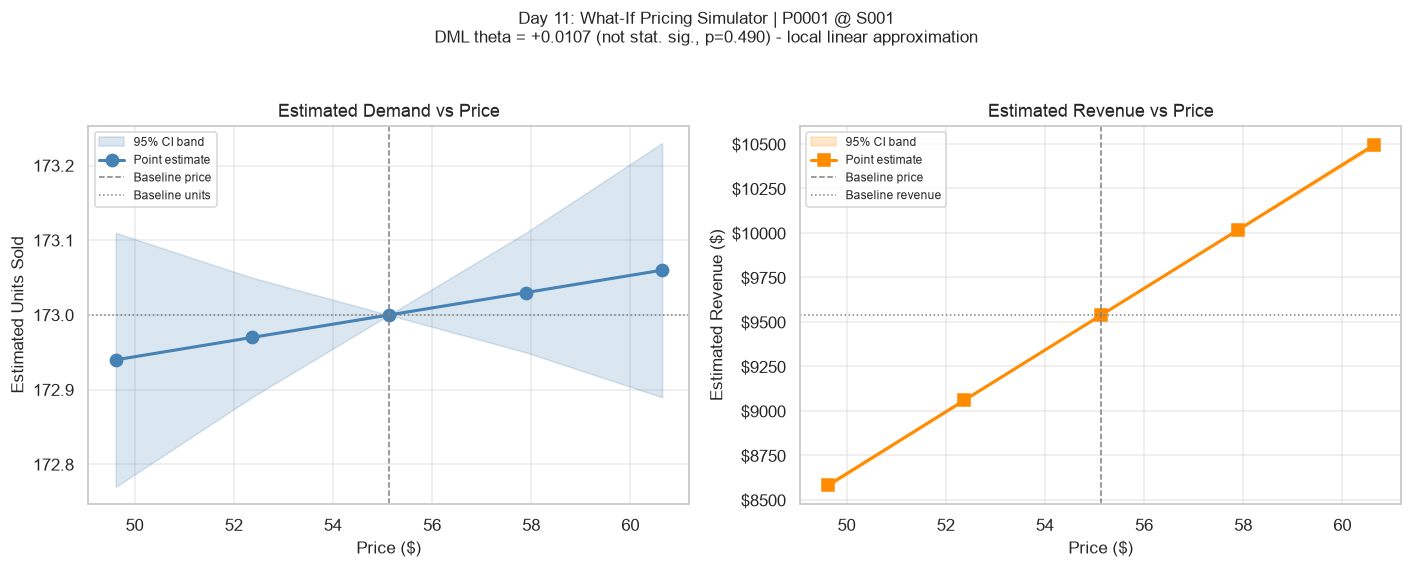

In [8]:
# Cell 8: Revenue and demand charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

prices = scenarios_df['Price ($)'].values
units  = scenarios_df['Est Units Sold'].values
revs   = scenarios_df['Est Revenue ($)'].values
u_lo   = scenarios_df['Est Units (CI low)'].values
u_hi   = scenarios_df['Est Units (CI high)'].values
r_lo   = prices * u_lo
r_hi   = prices * u_hi

# Panel A: Estimated Units Sold
ax = axes[0]
ax.fill_between(prices, u_lo, u_hi, alpha=0.2, color='steelblue', label='95% CI band')
ax.plot(prices, units, 'o-', color='steelblue', linewidth=2, markersize=8, label='Point estimate')
ax.axvline(BASE_PRICE, color='grey', linestyle='--', linewidth=1, label='Baseline price')
ax.axhline(BASE_UNITS, color='grey', linestyle=':', linewidth=1, label='Baseline units')
ax.set_xlabel('Price ($)', fontsize=11)
ax.set_ylabel('Estimated Units Sold', fontsize=11)
ax.set_title('Estimated Demand vs Price', fontsize=12)
ax.legend(fontsize=8)
ax.grid(alpha=0.4)

# Panel B: Estimated Revenue
ax = axes[1]
ax.fill_between(prices, r_lo, r_hi, alpha=0.2, color='darkorange', label='95% CI band')
ax.plot(prices, revs, 's-', color='darkorange', linewidth=2, markersize=8, label='Point estimate')
ax.axvline(BASE_PRICE, color='grey', linestyle='--', linewidth=1, label='Baseline price')
ax.axhline(BASE_REV, color='grey', linestyle=':', linewidth=1, label='Baseline revenue')
ax.set_xlabel('Price ($)', fontsize=11)
ax.set_ylabel('Estimated Revenue ($)', fontsize=11)
ax.set_title('Estimated Revenue vs Price', fontsize=12)
ax.legend(fontsize=8)
ax.grid(alpha=0.4)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.0f'))

plt.suptitle(
    f'Day 11: What-If Pricing Simulator | {PRODUCT_ID} @ {STORE_ID}\n'
    f'DML theta = {THETA:+.4f} (not stat. sig., p={P_VALUE:.3f}) - local linear approximation',
    fontsize=11, y=1.03
)
plt.tight_layout()
plt.show()

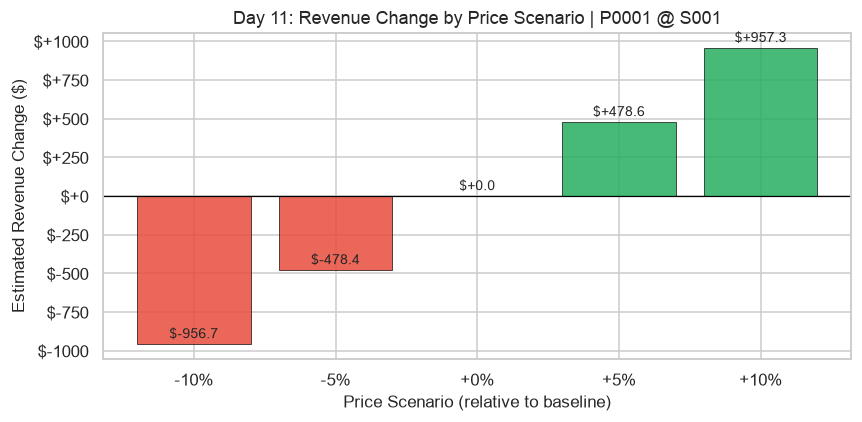


Note: 0% scenario = baseline (no change). Green bars = revenue increase.


In [9]:
# Cell 9: Revenue change bar chart
fig, ax = plt.subplots(figsize=(8, 4))

bar_colors = ['#27ae60' if r >= 0 else '#e74c3c' for r in scenarios_df['Rev Change ($)']]
bars = ax.bar(
    scenarios_df['Scenario'],
    scenarios_df['Rev Change ($)'],
    color=bar_colors, edgecolor='black', linewidth=0.5, alpha=0.85
)

max_rev_chg = scenarios_df['Rev Change ($)'].abs().max()
for bar, val in zip(bars, scenarios_df['Rev Change ($)']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max_rev_chg * 0.02,
        f'${val:+.1f}',
        ha='center', va='bottom', fontsize=9
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Price Scenario (relative to baseline)', fontsize=11)
ax.set_ylabel('Estimated Revenue Change ($)', fontsize=11)
ax.set_title(f'Day 11: Revenue Change by Price Scenario | {PRODUCT_ID} @ {STORE_ID}', fontsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%+.0f'))
plt.tight_layout()
plt.show()

print('\nNote: 0% scenario = baseline (no change). Green bars = revenue increase.')

## 6 · Save Simulator Results for Day 12

In [10]:
# Cell 10: Save simulator results
import json as _json
sim_output = {
    'product_id': PRODUCT_ID,
    'store_id': STORE_ID,
    'baseline_price': BASE_PRICE,
    'baseline_units': BASE_UNITS,
    'baseline_revenue': BASE_REV,
    'baseline_inventory': BASE_INV,
    'dml_theta': THETA,
    'dml_ci_low': CI_LOW,
    'dml_ci_high': CI_HIGH,
    'dml_p_value': P_VALUE,
    'price_obs_min': float(PRICE_OBS_MIN),
    'price_obs_max': float(PRICE_OBS_MAX),
    'scenarios': scenarios_df.to_dict(orient='records'),
}

sim_path = PROJECT_ROOT / 'data' / 'processed' / 'pricing_simulator_results.json'
with open(sim_path, 'w') as f:
    _json.dump(sim_output, f, indent=2, default=str)

print(f'Simulator results saved to: {sim_path}')

Simulator results saved to: /Users/hasikaippili/Documents/EconoCausal/data/processed/pricing_simulator_results.json


## 7 · Summary and Interpretation

In [11]:
# Cell 11: Summary
print('=' * 70)
print('DAY 11 - PRICING SIMULATOR SUMMARY')
print('=' * 70)
print(f'Product: {PRODUCT_ID} | Store: {STORE_ID}')
print(f'Baseline price   : ${BASE_PRICE:.2f}')
print(f'Baseline units   : {BASE_UNITS:.0f}')
print(f'Baseline revenue : ${BASE_REV:.2f}')
print()
print(f'DML theta (Spec 1) : {THETA:+.6f} units per $1 price increase')
print(f'  95% CI           : [{CI_LOW:.6f}, {CI_HIGH:.6f}]')
print(f'  p-value          : {P_VALUE:.4f}')
print()
print('Scenario Summary:')
for _, row in scenarios_df.iterrows():
    extrap = ' <- extrapolates beyond observed prices' if row['Extrapolates'] else ''
    print(
        f"  {row['Scenario']:>5}: price=${row['Price ($)']:>6.2f}, "
        f"est units={row['Est Units Sold']:>6.1f}, "
        f"est revenue=${row['Est Revenue ($)']:>8.2f} "
        f"(Delta${row['Rev Change ($)']:>+8.2f}){extrap}"
    )
print()
print('IMPORTANT DISCLAIMERS:')
print('  1. This is a LOCAL LINEAR APPROXIMATION, not a trained demand model.')
print('  2. The DML price coefficient is NOT statistically significant.')
print('  3. Large CI uncertainty means revenue estimates could be very different.')
print('  4. Revenue != Profit (unit costs unavailable).')
print('  5. Missing data: promotions, competitor prices, holidays, costs.')
print('  6. Do not use for automatic pricing decisions.')
print('=' * 70)

DAY 11 - PRICING SIMULATOR SUMMARY
Product: P0001 | Store: S001
Baseline price   : $55.13
Baseline units   : 173
Baseline revenue : $9537.49

DML theta (Spec 1) : +0.010699 units per $1 price increase
  95% CI           : [-0.019671, 0.041069]
  p-value          : 0.4899

Scenario Summary:
   -10%: price=$ 49.62, est units= 172.9, est revenue=$ 8580.81 (Delta$ -956.68)
    -5%: price=$ 52.37, est units= 173.0, est revenue=$ 9059.07 (Delta$ -478.42)
    +0%: price=$ 55.13, est units= 173.0, est revenue=$ 9537.49 (Delta$   +0.00)
    +5%: price=$ 57.89, est units= 173.0, est revenue=$10016.07 (Delta$ +478.58)
   +10%: price=$ 60.64, est units= 173.1, est revenue=$10494.82 (Delta$ +957.33)

IMPORTANT DISCLAIMERS:
  1. This is a LOCAL LINEAR APPROXIMATION, not a trained demand model.
  2. The DML price coefficient is NOT statistically significant.
  3. Large CI uncertainty means revenue estimates could be very different.
  4. Revenue != Profit (unit costs unavailable).
  5. Missing data: p